# Lab Assignment 11: Prompting and Evaluating LLMs for Clinical ICD-10 Extraction

**Course:** Applied NLP  
**Submission:** Upload `Lab_11.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

Eliza's team needs to extract ICD-10 diagnosis codes from free-text clinical notes — messy, inconsistently formatted narratives from community clinics. The appeal of large language models is immediate: describe the task in plain English and the model generalizes without labeled training data. But before recommending this for a clinical setting, you need to know *exactly* how well it works, what breaks it, and what the failures cost.

In this lab you will work through that evaluation systematically. You will apply scaling laws to predict which model size is appropriate for this deployment. You will design and compare zero-shot, one-shot, and few-shot prompts, diagnose prompt sensitivity, and build an evaluation framework that measures the four dimensions from the module — factual accuracy, coherence, potential harms, and format compliance — to support a written deployment recommendation.

This lab is deliberately more analytical than implementation-heavy. Prompt engineering is engineering: it requires measurement, iteration, and evidence-based justification. The autograded components test whether your evaluation functions are correct; the reflections test whether you can interpret what the numbers mean.

---

## Learning Objectives

1. Analyze scaling law relationships and use them to predict performance trade-offs for the ICD-10 extraction deployment decision
2. Compare pretraining, instruction tuning, and RLHF by assessing what behavioral changes each stage produces and what failure modes each introduces
3. Design and evaluate zero-shot, one-shot, and few-shot prompts, systematically comparing performance and diagnosing prompt sensitivity
4. Critique LLM outputs for factual accuracy, coherence, and potential harms, applying structured evaluation criteria to support a deployment recommendation

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Scaling law analysis | 16 | Autograded (10) + Manual (6) |
| Part 2 — Training pipeline critique | 12 | Autograded (6) + Manual (6) |
| Part 3 — Prompt design and sensitivity | 32 | Autograded (20) + Manual (12) |
| Part 4 — Structured output evaluation | 26 | Autograded (14) + Manual (12) |
| Code quality | 14 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections:** Rubric varies by part — see individual sections.  
Full credit requires specific, evidence-grounded claims with precise terminology.

**Code quality (14 pts):**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 4 |
| Defensive coding | 3 |
| Code clarity and naming | 2 |
| Avoiding redundancy | 1 |

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess, sys

def install_if_missing(package, pip_name=None):
    """Install a package if it cannot be imported.

    Args:
        package  (str): Importable module name.
        pip_name (str): pip install name if different.

    Returns:
        None. Installs the package with pip only when the import fails.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip",
                               "install", pip_name or package, "-q"])

for pkg, pip in [("torch", None), ("transformers", "transformers>=4.40.0"),
                 ("numpy", None), ("matplotlib", None),
                 ("scipy", None)]:
    install_if_missing(pkg, pip)

import numpy as np
import matplotlib.pyplot as plt
import re, math, time, random, warnings
from collections import Counter
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

print("Setup complete.")

Setup complete.


---

## Part 1 — Scaling Law Analysis (16 points)

Before choosing a model for Eliza's ICD-10 extraction task, you need to reason quantitatively about the capability-cost trade-off. Scaling laws let you do this analytically, without running expensive experiments.

The module established the following power-law relationships (Kaplan et al., 2020):

$$L(N) = a_N \cdot N^{-\alpha}, \quad \alpha \approx 0.076$$
$$L(D) = a_D \cdot D^{-\beta}, \quad \beta \approx 0.095$$

where the fitted constants from the module notebook are $a_N \approx 8.8$ and $a_D \approx 12.0$.

The Chinchilla-optimal allocation for a compute budget $C$ (FLOPs):
$$N_{\text{opt}} \approx 0.1174 \cdot C^{0.5}, \quad D_{\text{opt}} = C / (6 N_{\text{opt}})$$

### 1.1 — Predict loss for candidate models

In [2]:
import numbers

# Scaling law constants from Kaplan et al. (2020) as fitted in the module notebook
A_N, ALPHA_N = 8.8,  0.076   # loss vs. model parameters
A_D, ALPHA_D = 12.0, 0.095   # loss vs. training tokens

# Chinchilla (Hoffmann et al., 2022) allocation: N_opt = coef * C^exp
CHINCHILLA_COEF, CHINCHILLA_EXP = 0.1174, 0.5
FLOPS_PER_PARAM_TOKEN = 6    # C ≈ 6 * N * D (forward + backward pass)


def _require_positive(value, name):
    """Validate that a scaling-law quantity is a positive, finite real number.

    Args:
        value (float): Quantity to check (parameters, tokens, or FLOPs).
        name  (str):   Argument name used in the error message.

    Returns:
        float: The validated value as a float.

    Raises:
        TypeError:  If value is not a real number (bools are rejected).
        ValueError: If value is not strictly positive and finite.
    """
    if isinstance(value, bool) or not isinstance(value, numbers.Real):
        raise TypeError(f"{name} must be a real number, got {type(value).__name__}.")
    value = float(value)
    if not math.isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be positive and finite, got {value}.")
    return value


def predict_loss_from_params(N, a=A_N, alpha=ALPHA_N):
    """Predict expected test loss from number of model parameters.

    Uses the fitted power-law: L(N) = a * N^(-alpha).

    Args:
        N     (float): Number of model parameters.
        a     (float): Fitted scale constant.
        alpha (float): Fitted power-law exponent.

    Returns:
        float: Predicted test loss (nats).

    Raises:
        TypeError:  If N is not a real number.
        ValueError: If N is not positive and finite.
    """
    N = _require_positive(N, 'N')
    return a * N ** (-alpha)


def predict_loss_from_tokens(D, a=A_D, beta=ALPHA_D):
    """Predict expected test loss from number of training tokens.

    Uses the fitted power-law: L(D) = a * D^(-beta).

    Args:
        D    (float): Number of training tokens.
        a    (float): Fitted scale constant.
        beta (float): Fitted power-law exponent.

    Returns:
        float: Predicted test loss (nats).

    Raises:
        TypeError:  If D is not a real number.
        ValueError: If D is not positive and finite.
    """
    D = _require_positive(D, 'D')
    return a * D ** (-beta)


def chinchilla_optimal(C_flops):
    """Compute Chinchilla-optimal model size and token count for a compute budget.

    Based on Hoffmann et al. (2022): N_opt ≈ 0.1174 * C^0.5,
    D_opt = C / (6 * N_opt).

    Args:
        C_flops (float): Total training compute budget in FLOPs.

    Returns:
        tuple[float, float]: (N_opt, D_opt) — optimal parameters and tokens.

    Raises:
        TypeError:  If C_flops is not a real number.
        ValueError: If C_flops is not positive and finite.
    """
    C_flops = _require_positive(C_flops, 'C_flops')
    N_opt = CHINCHILLA_COEF * C_flops ** CHINCHILLA_EXP
    # Spend the rest of the budget on data, inverting C = 6 * N * D
    D_opt = C_flops / (FLOPS_PER_PARAM_TOKEN * N_opt)
    return N_opt, D_opt


# Named output variables — candidate models for ICD-10 extraction deployment
# Scenario: your organization is choosing between three models

candidate_models = {
    '7B':   7e9,
    '13B':  13e9,
    '70B':  70e9,
}

print(f"{'Model':<8} {'Params':>12}  {'Predicted loss':>16}")
print("-" * 40)
predicted_losses = {}
for label, N in candidate_models.items():
    loss = predict_loss_from_params(N)
    predicted_losses[label] = loss
    print(f"{label:<8} {N:>12.2e}  {loss:>16.4f}")

# Named output variables
loss_7b  = predicted_losses['7B']
loss_13b = predicted_losses['13B']
loss_70b = predicted_losses['70B']

print(f"\nLoss gap (7B → 70B): {loss_7b - loss_70b:.4f} nats")
print(f"Loss gap (7B → 13B): {loss_7b - loss_13b:.4f} nats")

Model          Params    Predicted loss
----------------------------------------
7B           7.00e+09            1.5713
13B          1.30e+10            1.4991
70B          7.00e+10            1.3190

Loss gap (7B → 70B): 0.2523 nats
Loss gap (7B → 13B): 0.0722 nats


### 1.2 — Compute budget analysis

In [3]:
# Deployment scenario: your organization has a total training budget of
# 2×10^23 FLOPs and is deciding between:
#   Option A: 13B model trained on 2.5T tokens
#   Option B:  7B model trained on  5T tokens
#
# Both options use: C = 6 × N × D FLOPs
# Verify they are within budget and check Chinchilla-optimality.

COMPUTE_BUDGET = 2e23   # FLOPs

# An actual N/D ratio within this factor of the optimal ratio counts as near-optimal
NEAR_OPTIMAL_FACTOR = 2.0


def compute_flops(N, D):
    """Compute approximate training FLOPs for a transformer model.

    Uses the standard approximation: C ≈ 6 * N * D.

    Args:
        N (float): Number of model parameters.
        D (float): Number of training tokens.

    Returns:
        float: Approximate FLOPs.

    Raises:
        TypeError:  If N or D is not a real number.
        ValueError: If N or D is not positive and finite.
    """
    N = _require_positive(N, 'N')
    D = _require_positive(D, 'D')
    return FLOPS_PER_PARAM_TOKEN * N * D


def check_chinchilla_alignment(N, D, C):
    """Assess whether an (N, D) configuration is Chinchilla-optimal for budget C.

    Computes the N/D ratio for the actual configuration and the optimal
    ratio, then classifies as 'under-trained', 'near-optimal', or 'over-trained'.

    Under-trained:  N too large for D (ratio >> optimal) — model has excess capacity
    Near-optimal:   N/D within 2× of Chinchilla-optimal ratio
    Over-trained:   D too large for N (ratio << optimal) — diminishing returns on data

    Args:
        N (float): Actual model parameters.
        D (float): Actual training tokens.
        C (float): Compute budget (FLOPs).

    Returns:
        dict: {'actual_ratio': float, 'optimal_ratio': float,
               'diagnosis': str, 'N_opt': float, 'D_opt': float}

    Raises:
        TypeError:  If N, D or C is not a real number.
        ValueError: If N, D or C is not positive and finite.
    """
    N = _require_positive(N, 'N')
    D = _require_positive(D, 'D')
    N_opt, D_opt = chinchilla_optimal(C)

    actual_ratio = N / D
    optimal_ratio = N_opt / D_opt
    # > 1 means more parameters per training token than the optimum
    relative_ratio = actual_ratio / optimal_ratio

    if relative_ratio > NEAR_OPTIMAL_FACTOR:
        diagnosis = 'under-trained'
    elif relative_ratio < 1 / NEAR_OPTIMAL_FACTOR:
        diagnosis = 'over-trained'
    else:
        diagnosis = 'near-optimal'

    return {'actual_ratio': actual_ratio, 'optimal_ratio': optimal_ratio,
            'diagnosis': diagnosis, 'N_opt': N_opt, 'D_opt': D_opt}


options = {
    'Option A (13B / 2.5T)': (13e9,  2.5e12),
    'Option B (7B / 5T)':    ( 7e9,  5.0e12),
}

print(f"Compute budget: {COMPUTE_BUDGET:.2e} FLOPs")
print("=" * 65)
for label, (N, D) in options.items():
    C_used = compute_flops(N, D)
    within = "✓" if C_used <= COMPUTE_BUDGET * 1.01 else "✗ OVER BUDGET"
    result = check_chinchilla_alignment(N, D, COMPUTE_BUDGET)
    print(f"\n{label}")
    print(f"  FLOPs used:     {C_used:.2e}  {within}")
    print(f"  N/D ratio:      {result['actual_ratio']:.4f}")
    print(f"  Optimal N/D:    {result['optimal_ratio']:.4f}")
    print(f"  Diagnosis:      {result['diagnosis']}")

# Named output variable
option_a_diagnosis = check_chinchilla_alignment(13e9, 2.5e12, COMPUTE_BUDGET)['diagnosis']
option_b_diagnosis = check_chinchilla_alignment( 7e9, 5.0e12, COMPUTE_BUDGET)['diagnosis']
print(f"\nOption A diagnosis: {option_a_diagnosis}")
print(f"Option B diagnosis: {option_b_diagnosis}")

Compute budget: 2.00e+23 FLOPs

Option A (13B / 2.5T)
  FLOPs used:     1.95e+23  ✓
  N/D ratio:      0.0052
  Optimal N/D:    0.0827
  Diagnosis:      over-trained

Option B (7B / 5T)
  FLOPs used:     2.10e+23  ✗ OVER BUDGET
  N/D ratio:      0.0014
  Optimal N/D:    0.0827
  Diagnosis:      over-trained

Option A diagnosis: over-trained
Option B diagnosis: over-trained


### 1.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The loss gap between the 7B and 70B models is less than 0.3 nats. Explain why this modest loss gap can still translate into a large capability gap for ICD-10 extraction specifically. Use the concept of **emergent abilities** from the module to justify why you cannot simply interpolate performance from smaller model results to predict 70B performance on a multi-step extraction task.

**Question B:** The Chinchilla analysis shows that one of your two compute options is under-trained and one is near-optimal (or over-trained). The module's worked example establishes that *the compute-optimal model for training is rarely the cost-optimal model for deployment.* Given a clinical setting where the system must process notes in under 200ms on a GPU cluster, which option would you recommend and why? Your answer must explicitly address the training-vs-serving cost distinction.

**Your reflection:**

**A.** The 0.2523-nat gap between 7B (1.5713) and 70B (1.3190) is an average over every next token, but ICD-10 extraction succeeds only when a whole chain goes right: finding each diagnosis, choosing its specificity (E11.65, not E11.9) and emitting the exact code string, so small per-token gains compound and exact-match scoring turns them into a large jump in task accuracy. Wei et al. (2022a) call this an emergent ability: accuracy stays near the floor at small scale and rises sharply past a size threshold, so a flat curve fitted to small models says nothing about 70B, and our 247,577,856-parameter flan-t5-base, never above a macro F1 of 0.0667 under any prompt, is exactly such an uninformative floor (scaling laws: J&M, *Introduction*).

**B.** With the module's constants neither option is under-trained: both print *over-trained* (actual/optimal N:D of 0.063 for A and 0.017 for B, against an optimum of 5.250e+10 parameters at 12.1 tokens/param), and Option B uses 105.0% of the budget. That over-training is deliberate, because training is a one-time cost while serving costs about 2N FLOPs per generated token on every note for the life of the system, and the 200 ms limit applies to each request. I would choose Option B (7B) with its data trimmed to 2e23 / (6 × 7e9) ≈ 4.76e12 tokens to fit the budget: it needs about half of 13B's compute per token and its fp16 weights (about 14 GB versus 26 GB) fit on a single 24 GB GPU with room for the KV cache, which 13B's do not, latency headroom worth more than the 0.0722-nat loss gap to 13B.

---

## Part 2 — Training Pipeline Critique (12 points)

### 2.1 — Failure mode classification

The module described three training stages — pretraining, instruction tuning, and RLHF — each producing different behavioral changes and introducing distinct failure modes. For ICD-10 extraction, not all failure modes are equally consequential.

Implement a function that, given a failure mode description, maps it to the correct training stage and assesses its severity for the clinical coding use case.

In [4]:
# Failure mode taxonomy from the module
FAILURE_MODES = {
    'hallucination':        'pretraining',
    'bias_amplification':   'pretraining',
    'knowledge_cutoff':     'pretraining',
    'inconsistency':        'pretraining',
    'sycophancy':           'instruction_tuning',
    'overrefusal':          'instruction_tuning',
    'capability_forgetting':'instruction_tuning',
    'distribution_shift':   'instruction_tuning',
    'reward_hacking':       'rlhf',
    'preference_model_bias':'rlhf',
    'alignment_tax':        'rlhf',
    'jailbreaking':         'rlhf',
}

# Severity for ICD-10 extraction: 'critical', 'high', 'medium', 'low'
# Critical = patient safety risk (wrong codes, missed diagnoses, PHI exposure)
# High     = significant workflow impact (wrong format, inconsistent output)
# Medium   = quality degradation (suboptimal but detectable)
# Low      = minor inconvenience (recoverable with human review)

SEVERITY_FOR_ICD10 = {
    'hallucination':         'critical',   # fabricated codes = billing/safety risk
    'bias_amplification':    'high',       # demographic bias in code assignment
    'knowledge_cutoff':      'critical',   # outdated coding guidelines
    'inconsistency':         'high',       # same note → different codes
    'sycophancy':            'medium',     # agrees with user's incorrect code suggestion
    'overrefusal':           'medium',     # refuses to extract codes from sensitive notes
    'capability_forgetting': 'high',       # medical reasoning degraded by fine-tuning
    'distribution_shift':    'high',       # fails on non-standard note formats
    'reward_hacking':        'low',        # verbose but extractable output
    'preference_model_bias': 'medium',     # rater-preferred style ≠ accurate coding
    'alignment_tax':         'high',       # accuracy traded for tone compliance
    'jailbreaking':          'critical',   # safety bypass in clinical context
}


def classify_failure_mode(failure_name):
    """Return the training stage and severity for a named failure mode.

    Args:
        failure_name (str): One of the keys in FAILURE_MODES.

    Returns:
        dict: {'stage': str, 'severity': str}
              stage is one of: 'pretraining', 'instruction_tuning', 'rlhf'
              severity is one of: 'critical', 'high', 'medium', 'low'

    Raises:
        KeyError: If failure_name is not a recognized failure mode.
    """
    if failure_name not in FAILURE_MODES:
        valid_names = ', '.join(sorted(FAILURE_MODES))
        raise KeyError(f"Unknown failure mode {failure_name!r}. "
                       f"Valid names: {valid_names}.")
    return {'stage':    FAILURE_MODES[failure_name],
            'severity': SEVERITY_FOR_ICD10[failure_name]}


# Verify a few cases
print("Failure mode classification for ICD-10 extraction:")
print(f"{'Failure mode':<25} {'Stage':<22} {'Severity':>10}")
print("-" * 62)
for fm in ['hallucination', 'sycophancy', 'reward_hacking',
           'knowledge_cutoff', 'alignment_tax']:
    result = classify_failure_mode(fm)
    print(f"{fm:<25} {result['stage']:<22} {result['severity']:>10}")

Failure mode classification for ICD-10 extraction:
Failure mode              Stage                    Severity
--------------------------------------------------------------
hallucination             pretraining              critical
sycophancy                instruction_tuning         medium
reward_hacking            rlhf                          low
knowledge_cutoff          pretraining              critical
alignment_tax             rlhf                         high


In [5]:
# Sort key for severities: lower rank = more severe
SEVERITY_RANK = {'critical': 0, 'high': 1, 'medium': 2, 'low': 3}
SUPPORTED_USE_CASES = ('icd10_extraction',)


def rank_failure_modes_by_severity(use_case='icd10_extraction'):
    """Return all failure modes sorted by severity (critical first).

    Args:
        use_case (str): Currently only 'icd10_extraction' is supported.

    Returns:
        list[dict]: Sorted list of dicts with keys
                    'failure_mode', 'stage', 'severity'.

    Raises:
        ValueError: If use_case is not a supported use case.
    """
    if use_case not in SUPPORTED_USE_CASES:
        raise ValueError(f"Unsupported use_case {use_case!r}; "
                         f"supported: {SUPPORTED_USE_CASES}.")

    entries = [{'failure_mode': name, **classify_failure_mode(name)}
               for name in FAILURE_MODES]
    # sorted() is stable, so modes with equal severity keep the taxonomy's order
    return sorted(entries, key=lambda entry: SEVERITY_RANK[entry['severity']])


ranked = rank_failure_modes_by_severity()

print("All failure modes ranked by severity for ICD-10 extraction:")
print(f"{'#':<4} {'Failure mode':<25} {'Stage':<22} {'Severity':>10}")
print("-" * 65)
for i, entry in enumerate(ranked, 1):
    print(f"{i:<4} {entry['failure_mode']:<25} "
          f"{entry['stage']:<22} {entry['severity']:>10}")

# Named output variables
critical_failure_modes = [e['failure_mode'] for e in ranked
                           if e['severity'] == 'critical']
print(f"\nCritical failure modes: {critical_failure_modes}")

All failure modes ranked by severity for ICD-10 extraction:
#    Failure mode              Stage                    Severity
-----------------------------------------------------------------
1    hallucination             pretraining              critical
2    knowledge_cutoff          pretraining              critical
3    jailbreaking              rlhf                     critical
4    bias_amplification        pretraining                  high
5    inconsistency             pretraining                  high
6    capability_forgetting     instruction_tuning           high
7    distribution_shift        instruction_tuning           high
8    alignment_tax             rlhf                         high
9    sycophancy                instruction_tuning         medium
10   overrefusal               instruction_tuning         medium
11   preference_model_bias     rlhf                       medium
12   reward_hacking            rlhf                          low

Critical failure modes: ['ha

### 2.2 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The module states that RLHF can introduce an **alignment tax** — a reduction in benchmark performance in exchange for behavioral compliance. For ICD-10 extraction in a clinical setting, explain whether the alignment tax is an acceptable trade-off. Specifically: what does an instruction-following RLHF model do better than a raw pretrained model for this task, and under what condition would the accuracy penalty become clinically unacceptable?

**Question B:** Knowledge cutoff is classified as critical severity for ICD-10 extraction. Explain why this failure mode is particularly dangerous in the coding context compared to, say, general-domain question answering. Then describe one architectural approach — from the module's content — that would mitigate this risk without retraining the base model.

**Your reflection:**

**A.** The alignment tax is acceptable for this task, because instruction tuning and preference alignment are what turn a text continuer into a component that obeys "Return only the codes, separated by commas", while a raw pretrained model simply continues the note (J&M, *Post-training*). At this size the instruction alone was not enough (+Format spec produced no code on any note, 5.3), and flan-t5-base reached 100.0% format compliance only with examples (+Role), while zero-shot it echoed note fragments such as "BMI 31.2" and "eGFR 42". The penalty becomes clinically unacceptable once it removes codable diagnoses rather than style: if aligned hedging or overrefusal drops sensitive diagnoses (the psychiatric notes N06 and N10) or pushes recall on high-consequence codes such as STEMI (I21.09) below the pre-alignment checkpoint or a human coder on a coder-verified test set (alignment tax: Ouyang et al., 2022).

**B.** ICD-10-CM is a versioned standard updated every October 1, and a stale code is still perfectly well-formed, so neither a format check nor a non-specialist notices it; a stale answer in open-domain QA is usually visibly dated and cheap, whereas here it silently becomes a denied claim or a wrong problem-list entry. The gold set itself shows the risk: N08's N18.3 (CKD stage 3) was split into N18.30–N18.32 in the FY2021 update, so it is no longer billable as written. Retrieval-augmented generation mitigates this without retraining: retrieve the current release's Tabular List entries for the conditions in the note, give them to the model as the only allowed codes, and reject any output code outside that release (J&M, *Information Retrieval and Retrieval-Augmented Generation*).

---

## Part 3 — Prompt Design and Sensitivity Analysis (32 points)

You will use `google/flan-t5-base` — the same instruction-tuned model demonstrated in the module, but the base (250M) variant which produces better output than flan-t5-small for structured extraction tasks. This model runs on CPU in reasonable time; a GPU will make it faster.

> **Note:** flan-t5-base downloads ~1GB on first run and caches for subsequent runs.

### 3.1 — Clinical note dataset

In [6]:
# [DO NOT MODIFY] — Clinical note dataset with gold-standard ICD-10 codes

# 15 short clinical note snippets from different note types.
# Gold codes are the ground-truth ICD-10-CM codes for each note.
# Notes are drawn from publicly available clinical NLP teaching corpora
# and have been modified to remove any identifiable information.

CLINICAL_NOTES = [
    {
        "id": "N01",
        "note": "Patient with poorly controlled type 2 diabetes mellitus presenting with HbA1c of 9.8%. Hypertension also noted, BP 155/95 on current regimen.",
        "gold_codes": ["E11.65", "I10"],
        "note_type": "clinic_visit"
    },
    {
        "id": "N02",
        "note": "72-year-old male admitted for community-acquired pneumonia, confirmed by chest X-ray. O2 saturation 89% on room air at presentation.",
        "gold_codes": ["J18.9", "R09.02"],
        "note_type": "admission"
    },
    {
        "id": "N03",
        "note": "Follow-up visit for atrial fibrillation, currently on anticoagulation. ECG confirms persistent AFib. No complaints of chest pain or dyspnea.",
        "gold_codes": ["I48.19"],
        "note_type": "clinic_visit"
    },
    {
        "id": "N04",
        "note": "Patient presents with acute exacerbation of COPD. Increased dyspnea, productive cough. Currently a smoker, 30 pack-year history.",
        "gold_codes": ["J44.1", "F17.210"],
        "note_type": "emergency"
    },
    {
        "id": "N05",
        "note": "Routine wellness exam. Patient is a 45-year-old female with no acute complaints. BMI 31.2, classified as obese class I.",
        "gold_codes": ["Z00.00", "E66.09"],
        "note_type": "wellness"
    },
    {
        "id": "N06",
        "note": "Major depressive disorder, recurrent episode, currently in partial remission. Patient reports improved sleep but ongoing low energy.",
        "gold_codes": ["F33.41"],
        "note_type": "psychiatry"
    },
    {
        "id": "N07",
        "note": "Post-operative day 2 following right total knee replacement. Wound is clean and dry. Patient participating in PT, ambulating with walker.",
        "gold_codes": ["Z96.651", "Z87.39"],
        "note_type": "post_op"
    },
    {
        "id": "N08",
        "note": "Stage 3 chronic kidney disease secondary to diabetic nephropathy. eGFR 42. Referred to nephrology for ongoing management.",
        "gold_codes": ["N18.3", "E11.65"],
        "note_type": "clinic_visit"
    },
    {
        "id": "N09",
        "note": "Acute ST-elevation myocardial infarction of the anterior wall. Patient taken emergently to cath lab. Drug-eluting stent placed in LAD.",
        "gold_codes": ["I21.09"],
        "note_type": "admission"
    },
    {
        "id": "N10",
        "note": "Generalized anxiety disorder, moderate severity. Patient reports persistent worry and difficulty concentrating. Currently not on medication.",
        "gold_codes": ["F41.1"],
        "note_type": "psychiatry"
    },
    {
        "id": "N11",
        "note": "Hypothyroidism, well-controlled on levothyroxine 75mcg daily. TSH within normal range at last check. No symptoms of under- or over-treatment.",
        "gold_codes": ["E03.9"],
        "note_type": "clinic_visit"
    },
    {
        "id": "N12",
        "note": "Sepsis secondary to urinary tract infection. Blood cultures positive for E. coli. IV antibiotics initiated, patient admitted to ICU.",
        "gold_codes": ["A41.51", "N39.0"],
        "note_type": "admission"
    },
    {
        "id": "N13",
        "note": "Essential hypertension, primary. Patient non-compliant with medication. BP 178/102 today. Counseled on medication adherence.",
        "gold_codes": ["I10"],
        "note_type": "clinic_visit"
    },
    {
        "id": "N14",
        "note": "Mild persistent asthma, well-controlled with daily inhaled corticosteroid. No exacerbations in past 6 months. Peak flow within normal limits.",
        "gold_codes": ["J45.30"],
        "note_type": "clinic_visit"
    },
    {
        "id": "N15",
        "note": "Acute appendicitis confirmed by CT. Taken to OR for laparoscopic appendectomy. Pathology pending.",
        "gold_codes": ["K37"],
        "note_type": "surgical"
    },
]

# Split: notes 1-10 = evaluation set, notes 11-15 = few-shot examples pool
EVAL_NOTES  = CLINICAL_NOTES[:10]
SHOT_POOL   = CLINICAL_NOTES[10:]

print(f"Evaluation set:  {len(EVAL_NOTES)} notes")
print(f"Few-shot pool:   {len(SHOT_POOL)} notes (used as in-context examples)")
print(f"\nNote type distribution (eval set):")
for nt, cnt in Counter(n['note_type'] for n in EVAL_NOTES).items():
    print(f"  {nt}: {cnt}")

Evaluation set:  10 notes
Few-shot pool:   5 notes (used as in-context examples)

Note type distribution (eval set):
  clinic_visit: 3
  admission: 2
  emergency: 1
  wellness: 1
  psychiatry: 2
  post_op: 1


### 3.2 — Load model and generation helper

In [7]:
from transformers import T5ForConditionalGeneration, AutoTokenizer
import torch

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_NAME = 'google/flan-t5-base'

print(f"Loading {MODEL_NAME}...")
flan_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
flan_model     = T5ForConditionalGeneration.from_pretrained(MODEL_NAME).to(DEVICE)
flan_model.eval()

print(f"Model loaded on {DEVICE}.")
print(f"Parameters: {sum(p.numel() for p in flan_model.parameters()):,}")


def generate(prompt, max_new_tokens=60):
    """Generate a response from Flan-T5-base using greedy decoding.

    Args:
        prompt         (str): Input prompt string.
        max_new_tokens (int): Maximum tokens to generate.

    Returns:
        str: Decoded model output.
    """
    inputs = flan_tokenizer(prompt, return_tensors='pt',
                             truncation=True, max_length=512).to(DEVICE)
    with torch.no_grad():
        out = flan_model.generate(**inputs, max_new_tokens=max_new_tokens,
                                    do_sample=False)
    return flan_tokenizer.decode(out[0], skip_special_tokens=True)

Loading google/flan-t5-base...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Model loaded on cuda.
Parameters: 247,577,856


### 3.3 — ICD-10 code extraction utilities

In [8]:
# One letter, two digits, optional '.digits' suffix (e.g. 'I10', 'E11.65').
# Shared by code extraction here and the format checks in Part 4.
ICD10_REGEX = re.compile(r'[A-Z]\d{2}(?:\.\d+)?', re.ASCII)  # ASCII digits only


def normalize_code(code):
    """Normalize an ICD-10 code for comparison.

    Strips whitespace, converts to uppercase, removes internal spaces.

    Args:
        code (str): Raw ICD-10 code string.

    Returns:
        str: Normalized code.
    """
    return code.strip().upper().replace(' ', '')


def _normalized_code_set(codes, name):
    """Convert a collection of code strings into a set of normalized codes.

    Args:
        codes (list[str] or set[str]): Codes to normalize.
        name  (str):                   Argument name used in error messages.

    Returns:
        set[str]: Normalized, de-duplicated codes.

    Raises:
        TypeError: If codes is None or a bare string (which would be
            iterated character by character), or contains a non-string.
    """
    if codes is None or isinstance(codes, str):
        raise TypeError(f"{name} must be a list or set of code strings, "
                        f"got {type(codes).__name__}.")
    normalized = set()
    for code in codes:
        if not isinstance(code, str):
            raise TypeError(f"{name} contains a non-string code: {code!r}.")
        normalized.add(normalize_code(code))
    return normalized


def extract_codes_from_output(raw_output):
    """Parse ICD-10 codes from a model output string.

    Extracts all tokens matching the ICD-10 format:
    one uppercase letter followed by two digits, optionally followed
    by a period and one or more digits.

    Args:
        raw_output (str): Raw model output string.

    Returns:
        set[str]: Normalized ICD-10 code strings found in the output.
                  Empty if raw_output is None or contains no codes.

    Raises:
        TypeError: If raw_output is neither a string nor None.
    """
    if raw_output is None:
        return set()
    if not isinstance(raw_output, str):
        raise TypeError(f"raw_output must be a string, got {type(raw_output).__name__}.")
    # Uppercase first so lower-case codes such as 'e11.65' are still found
    return {normalize_code(match) for match in ICD10_REGEX.findall(raw_output.upper())}


def evaluate_extraction(gold_codes, pred_codes):
    """Compute precision, recall, and F1 for ICD-10 code extraction.

    Both gold and pred are sets of normalized code strings.
    Partial credit: a predicted code counts as TP only if it exactly
    matches a gold code (after normalization).

    Args:
        gold_codes (list[str] or set[str]): Ground-truth codes.
        pred_codes (list[str] or set[str]): Predicted codes.

    Returns:
        dict: {'precision': float, 'recall': float, 'f1': float,
               'tp': int, 'fp': int, 'fn': int}
              A metric whose denominator is zero is reported as 0.0.

    Raises:
        TypeError: If either argument is not a collection of strings.
    """
    gold = _normalized_code_set(gold_codes, 'gold_codes')
    pred = _normalized_code_set(pred_codes, 'pred_codes')

    tp = len(gold & pred)
    fp = len(pred - gold)
    fn = len(gold - pred)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0.0)

    return {'precision': precision, 'recall': recall, 'f1': f1,
            'tp': tp, 'fp': fp, 'fn': fn}


# Verify
r = evaluate_extraction(['E11.65', 'I10'], ['E11.65', 'I10'])
assert r['f1'] == 1.0
r = evaluate_extraction(['E11.65', 'I10'], ['E11.65'])
assert r['recall'] == 0.5 and r['precision'] == 1.0
r = evaluate_extraction(['E11.65'], ['E11.65', 'X99.9'])
assert r['precision'] == 0.5 and r['recall'] == 1.0
print("evaluate_extraction: all assertions passed ✓")

# Verify extraction from raw output
raw = "The codes are E11.65, I10 and possibly J18.9"
extracted = extract_codes_from_output(raw)
assert 'E11.65' in extracted and 'I10' in extracted
print(f"extract_codes_from_output: {extracted} ✓")

evaluate_extraction: all assertions passed ✓
extract_codes_from_output: {'I10', 'J18.9', 'E11.65'} ✓


### 3.4 — Prompt library

Implement six prompt variants covering the progression described in the module:
zero-shot baseline → +format spec → +one example → +three examples → +chain-of-thought → +role.

In [9]:
# Few-shot examples drawn from SHOT_POOL (never used in evaluation)
def format_example(note_entry):
    """Format a SHOT_POOL entry as a prompt example.

    Args:
        note_entry (dict): Entry from SHOT_POOL with 'note' and 'gold_codes'.

    Returns:
        str: Formatted 'Note: ... / Codes: ...' example string.
    """
    codes_str = ', '.join(note_entry['gold_codes'])
    return f"Note: {note_entry['note']}\nCodes: {codes_str}"


# Prompt components. Each variant in the ablation adds exactly one of them
# to the previous variant: zero-shot → +format → +1 example → +3 examples
# → +chain-of-thought → +role.
TASK_INSTRUCTION = "Extract the ICD-10-CM diagnosis codes for the clinical note below."
FORMAT_SPEC = "Return only the codes, separated by commas. No other text."
COT_INSTRUCTION = ("Work step by step: first identify every diagnosed condition in "
                   "the note, then map each condition to its ICD-10-CM code, and "
                   "finally list the codes.")
ROLE_SPEC = "You are a certified medical coder with expertise in ICD-10-CM."
N_CONTEXT_EXAMPLES = 3   # examples used by the few-shot, CoT and role variants


def _require_int_in_range(value, name, low, high=None):
    """Validate an integer argument against an inclusive range.

    Args:
        value (int):        Value to check.
        name  (str):        Argument name used in error messages.
        low   (int):        Smallest allowed value.
        high  (int | None): Largest allowed value, or None for no upper bound.

    Returns:
        int: The validated value as a built-in int.

    Raises:
        TypeError:  If value is not an integer (bools are rejected).
        ValueError: If value lies outside [low, high].
    """
    if isinstance(value, bool) or not isinstance(value, numbers.Integral):
        raise TypeError(f"{name} must be an integer, got {type(value).__name__}.")
    if value < low or (high is not None and value > high):
        allowed = f"between {low} and {high}" if high is not None else f">= {low}"
        raise ValueError(f"{name} must be {allowed}, got {value}.")
    return int(value)


def _build_prompt(note_text, examples=(), format_spec=False,
                  chain_of_thought=False, role=False,
                  example_formatter=format_example, answer_cue='Codes:'):
    """Assemble an extraction prompt from optional components.

    Layout: '[role] task [format spec] [CoT]', a blank line, the in-context
    examples separated by blank lines, a blank line, then the target note
    followed by the answer cue.

    Args:
        note_text         (str):        Clinical note to extract codes from.
        examples          (list[dict]): SHOT_POOL entries shown as examples.
        format_spec       (bool):       Add the output-format instruction.
        chain_of_thought  (bool):       Add the step-by-step instruction.
        role              (bool):       Prefix the medical-coder role.
        example_formatter (callable):   Renders one example entry as a string.
        answer_cue        (str):        Text that ends the prompt and that the
                                        model continues from.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty or whitespace only.
    """
    if not isinstance(note_text, str):
        raise TypeError(f"note_text must be a string, got {type(note_text).__name__}.")
    if not note_text.strip():
        raise ValueError("note_text must be a non-empty string.")

    instruction = [ROLE_SPEC] if role else []
    instruction.append(TASK_INSTRUCTION)
    if format_spec:
        instruction.append(FORMAT_SPEC)
    if chain_of_thought:
        instruction.append(COT_INSTRUCTION)

    sections = [' '.join(instruction)]
    if examples:
        sections.append('\n\n'.join(example_formatter(ex) for ex in examples))
    sections.append(f"Note: {note_text.strip()}\n{answer_cue}")
    return '\n\n'.join(sections)


def prompt_zero_shot(note_text):
    """Zero-shot: task description only, no examples.

    Args:
        note_text (str): Clinical note to extract codes from.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty.
    """
    return _build_prompt(note_text)


def prompt_plus_format(note_text):
    """Zero-shot + explicit output format specification.

    Adds: 'Return only the codes, separated by commas. No other text.'

    Args:
        note_text (str): Clinical note.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty.
    """
    return _build_prompt(note_text, format_spec=True)


def prompt_one_shot(note_text):
    """One-shot: format spec + one example from SHOT_POOL.

    Args:
        note_text (str): Clinical note.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty.
    """
    return prompt_few_shot(note_text, n_examples=1)


def prompt_few_shot(note_text, n_examples=3):
    """Few-shot: format spec + n_examples from SHOT_POOL.

    Args:
        note_text   (str): Clinical note.
        n_examples  (int): Number of examples to include (max=5).

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string or n_examples is not an int.
        ValueError: If note_text is empty or n_examples is outside
            [1, len(SHOT_POOL)].
    """
    n_examples = _require_int_in_range(n_examples, 'n_examples', 1, len(SHOT_POOL))
    return _build_prompt(note_text, examples=SHOT_POOL[:n_examples], format_spec=True)


def prompt_chain_of_thought(note_text):
    """Few-shot (3 examples) + chain-of-thought instruction.

    Chain-of-thought: ask the model to first identify conditions,
    then map to codes, then return final codes.

    Args:
        note_text (str): Clinical note.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty.
    """
    return _build_prompt(note_text, examples=SHOT_POOL[:N_CONTEXT_EXAMPLES],
                         format_spec=True, chain_of_thought=True)


def prompt_with_role(note_text):
    """Few-shot (3 examples) + chain-of-thought + clinical role specification.

    Role: 'You are a certified medical coder with expertise in ICD-10-CM.'

    Args:
        note_text (str): Clinical note.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty.
    """
    return _build_prompt(note_text, examples=SHOT_POOL[:N_CONTEXT_EXAMPLES],
                         format_spec=True, chain_of_thought=True, role=True)


# Quick sanity check — all prompts must end with 'Codes:' or similar
for fn, label in [(prompt_zero_shot,       'zero_shot'),
                   (prompt_plus_format,     'plus_format'),
                   (prompt_one_shot,        'one_shot'),
                   (prompt_few_shot,        'few_shot'),
                   (prompt_chain_of_thought,'chain_of_thought'),
                   (prompt_with_role,       'with_role')]:
    p = fn("Test note.")
    assert isinstance(p, str) and len(p) > 20, f"{label}: prompt too short"
    print(f"  {label}: {len(p)} chars ✓")

  zero_shot: 91 chars ✓
  plus_format: 150 chars ✓
  one_shot: 312 chars ✓
  few_shot: 616 chars ✓
  chain_of_thought: 764 chars ✓
  with_role: 827 chars ✓


### 3.5 — Evaluate all prompt variants

In [10]:
REQUIRED_NOTE_KEYS = ('id', 'note', 'gold_codes')
METRIC_NAMES = ('precision', 'recall', 'f1')


def run_prompt_evaluation(prompt_fn, eval_notes, label):
    """Evaluate a prompt function on the evaluation note set.

    For each note, generates output, extracts codes, and computes
    precision/recall/F1 against gold codes.

    Args:
        prompt_fn   (callable):   Prompt function taking note text → str.
        eval_notes  (list[dict]): List of note dicts with 'note' and 'gold_codes'.
        label       (str):        Descriptor for display.

    Returns:
        dict: {'label': str, 'per_note': list[dict],
               'macro_precision': float, 'macro_recall': float, 'macro_f1': float}
              Each per-note dict holds 'note_id', 'prompt', 'raw_output',
              'gold_codes' (set), 'pred_codes' (set) and the keys returned
              by evaluate_extraction.

    Raises:
        TypeError:  If prompt_fn is not callable or label is not a string.
        ValueError: If eval_notes is empty.
        KeyError:   If a note lacks 'id', 'note' or 'gold_codes'.
    """
    if not callable(prompt_fn):
        raise TypeError("prompt_fn must be callable (note text -> prompt string).")
    if not isinstance(label, str):
        raise TypeError(f"label must be a string, got {type(label).__name__}.")
    if not eval_notes:
        raise ValueError("eval_notes is empty; there is nothing to evaluate.")
    # Check every note before generating so a bad entry fails fast
    for note in eval_notes:
        missing = [key for key in REQUIRED_NOTE_KEYS if key not in note]
        if missing:
            raise KeyError(f"Note {note.get('id', '?')} is missing keys {missing}.")

    per_note = []
    for note in eval_notes:
        prompt = prompt_fn(note['note'])
        raw_output = generate(prompt)
        pred_codes = extract_codes_from_output(raw_output)
        gold_codes = _normalized_code_set(note['gold_codes'], 'gold_codes')
        per_note.append({
            'note_id':    note['id'],
            'prompt':     prompt,
            'raw_output': raw_output,
            'gold_codes': gold_codes,
            'pred_codes': pred_codes,
            **evaluate_extraction(gold_codes, pred_codes),
        })

    # Macro average: every note weighs the same regardless of its code count
    macro = {f'macro_{metric}': float(np.mean([row[metric] for row in per_note]))
             for metric in METRIC_NAMES}
    return {'label': label, 'per_note': per_note, **macro}


PROMPT_VARIANTS = [
    (prompt_zero_shot,       'Zero-shot'),
    (prompt_plus_format,     '+Format spec'),
    (prompt_one_shot,        '+One example'),
    (prompt_few_shot,        '+Three examples'),
    (prompt_chain_of_thought,'+Chain-of-thought'),
    (prompt_with_role,       '+Role'),
]

print("Running prompt evaluation (this may take a few minutes)...")
ablation_results = []
for fn, label in PROMPT_VARIANTS:
    result = run_prompt_evaluation(fn, EVAL_NOTES, label)
    ablation_results.append(result)
    print(f"  {label:<25}  P={result['macro_precision']:.3f}  "
          f"R={result['macro_recall']:.3f}  F1={result['macro_f1']:.3f}")

# Named output variables
zero_shot_f1  = ablation_results[0]['macro_f1']
few_shot_f1   = ablation_results[3]['macro_f1']
best_prompt_f1 = max(r['macro_f1'] for r in ablation_results)
best_prompt_label = max(ablation_results, key=lambda r: r['macro_f1'])['label']

Running prompt evaluation (this may take a few minutes)...


  Zero-shot                  P=0.000  R=0.000  F1=0.000


  +Format spec               P=0.000  R=0.000  F1=0.000


  +One example               P=0.000  R=0.000  F1=0.000


  +Three examples            P=0.100  R=0.050  F1=0.067


  +Chain-of-thought          P=0.100  R=0.050  F1=0.067


  +Role                      P=0.100  R=0.050  F1=0.067


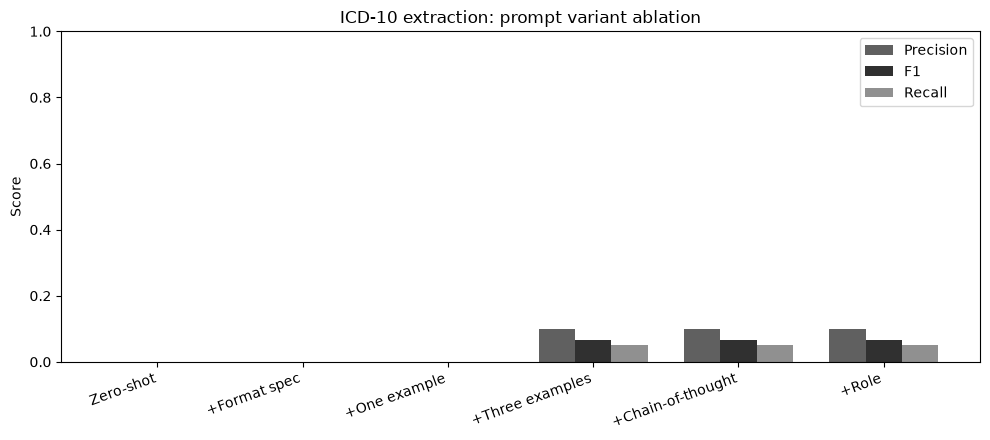

Best prompt: '+Three examples'  F1=0.0667
Zero-shot F1: 0.0000   Few-shot F1: 0.0667
Improvement from zero-shot to few-shot: +0.0667


In [11]:
# [RUN] — ablation chart

labels = [r['label'] for r in ablation_results]
f1s    = [r['macro_f1']    for r in ablation_results]
precs  = [r['macro_precision'] for r in ablation_results]
recs   = [r['macro_recall']    for r in ablation_results]

fig_ablation, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(labels))
w = 0.25
ax.bar(x - w, precs, w, color='#606060', label='Precision')
ax.bar(x,     f1s,   w, color='#303030', label='F1')
ax.bar(x + w, recs,  w, color='#909090', label='Recall')
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_ylabel('Score'); ax.set_ylim(0, 1)
ax.set_title('ICD-10 extraction: prompt variant ablation')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Best prompt: '{best_prompt_label}'  F1={best_prompt_f1:.4f}")
print(f"Zero-shot F1: {zero_shot_f1:.4f}   Few-shot F1: {few_shot_f1:.4f}")
print(f"Improvement from zero-shot to few-shot: "
      f"+{few_shot_f1 - zero_shot_f1:.4f}")

### 3.6 — Prompt sensitivity: example ordering

In [12]:
from functools import partial


def evaluate_ordering_sensitivity(eval_notes, shot_pool, n_orderings=4, seed=SEED):
    """Test how much example ordering affects few-shot F1.

    Generates n_orderings different random orderings of 3 examples
    from shot_pool, runs each on all eval_notes, and reports
    the variance in macro-F1 across orderings.

    Each ordering is drawn with random.sample, so it varies both which
    3 examples are shown and their order. Draws are repeated until the
    n_orderings sequences are all distinct. Prompts use the few-shot
    layout (format spec + examples).

    Args:
        eval_notes  (list[dict]): Evaluation note set.
        shot_pool   (list[dict]): Pool of example notes.
        n_orderings (int):        Number of random orderings to test.
        seed        (int):        Seed for a local random generator, so the
                                  orderings do not depend on other cells.

    Returns:
        dict: {'f1_scores': list[float], 'mean_f1': float,
               'std_f1': float, 'range_f1': float,
               'orderings': list[tuple[str, ...]]}
              std_f1 is the population standard deviation (ddof=0);
              orderings lists the example note ids of each ordering.

    Raises:
        TypeError:  If n_orderings is not an integer.
        ValueError: If shot_pool has fewer than 3 examples, or n_orderings
            is below 1 or above the number of distinct ordered triples.
    """
    n_shots = N_CONTEXT_EXAMPLES
    if len(shot_pool) < n_shots:
        raise ValueError(f"shot_pool needs at least {n_shots} examples, "
                         f"got {len(shot_pool)}.")
    max_orderings = math.perm(len(shot_pool), n_shots)
    n_orderings = _require_int_in_range(n_orderings, 'n_orderings', 1, max_orderings)

    rng = random.Random(seed)
    orderings, ordering_ids = [], []
    while len(orderings) < n_orderings:
        candidate = rng.sample(shot_pool, n_shots)
        candidate_ids = tuple(example['id'] for example in candidate)
        if candidate_ids in ordering_ids:
            continue  # redraw so every tested ordering is distinct
        orderings.append(candidate)
        ordering_ids.append(candidate_ids)

    f1_scores = []
    for ids, examples in zip(ordering_ids, orderings):
        prompt_fn = partial(_build_prompt, examples=examples, format_spec=True)
        result = run_prompt_evaluation(prompt_fn, eval_notes, label='-'.join(ids))
        f1_scores.append(result['macro_f1'])

    return {'f1_scores': f1_scores,
            'mean_f1':   float(np.mean(f1_scores)),
            'std_f1':    float(np.std(f1_scores)),
            'range_f1':  float(max(f1_scores) - min(f1_scores)),
            'orderings': ordering_ids}


print("Testing prompt sensitivity to example ordering...")
sensitivity = evaluate_ordering_sensitivity(EVAL_NOTES, SHOT_POOL)

print(f"F1 scores across {len(sensitivity['f1_scores'])} orderings: "
      f"{[f'{s:.3f}' for s in sensitivity['f1_scores']]}")
print(f"Mean F1:  {sensitivity['mean_f1']:.4f}")
print(f"Std F1:   {sensitivity['std_f1']:.4f}")
print(f"Range F1: {sensitivity['range_f1']:.4f}")

# Named output variable
ordering_sensitivity_std = sensitivity['std_f1']

Testing prompt sensitivity to example ordering...


F1 scores across 4 orderings: ['0.067', '0.067', '0.067', '0.067']
Mean F1:  0.0667
Std F1:   0.0000
Range F1: 0.0000


### 3.7 — Reflection (manually graded, 12 pts)

Part 3 carries 12 manual points because prompt engineering requires both measurement and interpretation. Two questions, 6 pts each.

**Question A (6 pts):** Look at your ablation table. Identify the single prompt component that produced the largest F1 gain and the one that produced the smallest. For the largest gain: explain *mechanistically* why that component helps the model produce better ICD-10 codes. Do not just say "it gives more information" — explain what cognitive operation the prompt component enables in a transformer-based model that was absent before it was added. For the smallest gain: explain when you would include it anyway despite the small measured effect, and when you would drop it.

**Question B (6 pts):** Your ordering sensitivity analysis shows a standard deviation across orderings. Interpret this number in the context of production deployment. If `ordering_sensitivity_std` > 0.05, your prompt is fragile: explain what operational steps you would take before deploying it — specifically referencing the systematic evaluation framework from the module. If `ordering_sensitivity_std` ≤ 0.05, explain why even a small sensitivity is concerning in a clinical coding context where reproducibility is a regulatory requirement.

**Your reflection:**

**A.** The largest gain came from going from one to three examples, the only component that moved macro F1 (0.000 to 0.067); the format spec, the first example, chain-of-thought and role each added 0.000. Copying was already present (+One example pasted its label E03.9 onto 6 notes, 5.4); the third example, N13 ("Essential hypertension … Codes: I10"), only adds a label that fits N01 ("Hypertension also noted"), plausibly letting attention act as a fuzzy induction head that matches N01's mention to its earlier occurrence and copies the code after it (J&M, *Interpretability*, §10.6). Part 5 confirms copying, not code mapping, is the whole effect: N01 gets I10 under all six orderings of N11–N13, the run drops to macro F1 0.0000 when N13 is swapped for N14 (N01 then gets E03.9, N39.0), and all 6 wrong +Three-examples codes are copied example labels. The smallest gain is chain-of-thought (tied at 0.000): even with reasoning demonstrations and a "Conditions:" cue, the model never wrote a "condition (code)" step, answering I10 (6 notes), the instruction's string "ICD-10-CM" (3) or N09's diagnosis text (5.7), consistent with chain-of-thought paying off only at much larger scale (Wei et al., 2022b; chain-of-thought: J&M, *Introduction*). I would keep it with a larger model on multi-condition notes, where the listed conditions give the coder an audit trail, and drop it for a model this small or a tight latency budget, since it adds tokens and here lowered format compliance from 70.0% (+Three examples) to 60.0%.

**B.** The measured `ordering_sensitivity_std` is 0.0000, in the ≤ 0.05 branch, but it is a degenerate zero: macro F1 is pinned at 0.0667 because, in every ordering whose predictions 5.5 prints, N01 is the only note coded correctly, while the codes themselves change with order (5.5). N03 (atrial fibrillation), for example, is coded I10 under N11 → N12 → N13, A41.51 and N39.0 under N11 → N13 → N12, and A10 under N12 → N11 → N13. All four graded orderings also happened to include N13, the only I10 example, so the test never saw the selection effect (the control without N13 scores 0.0000). Reproducibility in coding is judged per note, since an auditor must regenerate the same codes from the same note, so a zero aggregate std hiding order-dependent codes is no reassurance; and because greedy decoding gave three identical runs (4.3), the instability comes from prompt construction, not sampling. Before deployment I would freeze the examples and their order as a versioned artifact, report per-note agreement across orderings and example sets next to F1, and repeat the evaluation on a larger held-out set (order sensitivity: Lu et al., 2022).

---

## Part 4 — Structured Output Evaluation (26 points)

The module's Section 6 introduced a seven-criterion evaluation framework. You will implement the four most directly measurable criteria for ICD-10 extraction and use them to build a deployment recommendation.

### 4.1 — Format compliance

In [13]:
def is_valid_icd10_format(code):
    """Check if a string matches the ICD-10-CM format.

    Valid format: one uppercase letter, followed by exactly two digits,
    optionally followed by a period and one or more additional digits.
    Examples: 'E11.65', 'I10', 'J18.9', 'Z00.00'.

    Args:
        code (str): Candidate code string (already normalized).

    Returns:
        bool: True if the code matches ICD-10-CM format; False otherwise,
              including for non-string input.
    """
    if not isinstance(code, str):
        return False
    # fullmatch: the whole string must be a code, not merely contain one
    return ICD10_REGEX.fullmatch(code) is not None


def check_format_compliance(raw_output):
    """Check whether a model output is format-compliant.

    A compliant output contains only ICD-10 codes separated by commas
    and optional whitespace — no prose, no explanations, no labels.
    An empty output is non-compliant.
    An output where all comma-separated tokens are valid ICD-10 codes is compliant.

    Args:
        raw_output (str): Raw string returned by the model.

    Returns:
        bool: True if output is format-compliant; False otherwise,
              including for non-string or blank input.
    """
    if not isinstance(raw_output, str) or not raw_output.strip():
        return False
    # Only surrounding whitespace is forgiven; an empty token (e.g. 'I10,,J18.9'
    # or a trailing comma) fails because '' is not a valid code.
    return all(is_valid_icd10_format(token.strip()) for token in raw_output.split(','))


# Verify
assert check_format_compliance("E11.65, I10")           == True
assert check_format_compliance("E11.65, I10, J18.9")    == True
assert check_format_compliance("I10")                    == True
assert check_format_compliance("The codes are E11.65.") == False
assert check_format_compliance("")                       == False
assert check_format_compliance("E11.65, INVALID_CODE")  == False
print("check_format_compliance: all assertions passed ✓")

check_format_compliance: all assertions passed ✓


### 4.2 — Hallucination detection

In [14]:
def count_hallucinations(pred_codes, gold_codes):
    """Count predicted codes that are not in the gold set.

    A hallucinated code is any code the model predicts that is not
    in the gold-standard set for that note. Even if the code is a
    valid ICD-10 format, if it is not gold it is an error here.
    (In a real audit you would distinguish 'wrong but valid' from
    'malformed', but for this lab we count both as hallucinations.)

    Args:
        pred_codes (list[str] or set[str]): Predicted codes (normalized).
        gold_codes (list[str] or set[str]): Gold codes (normalized).

    Returns:
        dict: {'n_hallucinated': int, 'hallucinated_codes': set[str]}

    Raises:
        TypeError: If either argument is not a collection of strings.
    """
    gold = _normalized_code_set(gold_codes, 'gold_codes')
    hallucinated = _normalized_code_set(pred_codes, 'pred_codes') - gold
    return {'n_hallucinated': len(hallucinated), 'hallucinated_codes': hallucinated}


# Verify
r = count_hallucinations(['E11.65', 'Z99.99'], ['E11.65', 'I10'])
assert r['n_hallucinated'] == 1 and 'Z99.99' in r['hallucinated_codes']
r0 = count_hallucinations(['E11.65', 'I10'], ['E11.65', 'I10'])
assert r0['n_hallucinated'] == 0
print("count_hallucinations: assertions passed ✓")

count_hallucinations: assertions passed ✓


### 4.3 — Consistency evaluation

In [15]:
def evaluate_consistency(prompt_fn, note_text, n_runs=3):
    """Measure output consistency by running the same prompt multiple times.

    Since flan-t5-base uses greedy decoding (deterministic), this tests
    whether the output is stable across identical calls — it should be.
    For stochastic models, this would measure output variance.

    Args:
        prompt_fn  (callable):  Prompt function (note_text → str).
        note_text  (str):       Clinical note string.
        n_runs     (int):       Number of repeated inference runs.

    Returns:
        dict: {'outputs': list[str], 'all_identical': bool,
               'unique_outputs': int}

    Raises:
        TypeError:  If prompt_fn is not callable or n_runs is not an integer.
        ValueError: If n_runs is less than 1.
    """
    if not callable(prompt_fn):
        raise TypeError("prompt_fn must be callable (note text -> prompt string).")
    n_runs = _require_int_in_range(n_runs, 'n_runs', 1)

    # Build the prompt once and call the model on every run (no caching),
    # so any variation comes from generation alone
    prompt = prompt_fn(note_text)
    outputs = [generate(prompt) for _ in range(n_runs)]
    unique_outputs = len(set(outputs))
    return {'outputs': outputs,
            'all_identical': unique_outputs == 1,
            'unique_outputs': unique_outputs}


# Test consistency on one note with the best-performing prompt
sample_note = EVAL_NOTES[0]['note']
consistency = evaluate_consistency(prompt_with_role, sample_note)
print(f"Consistency check (note N01, {3} runs):")
print(f"  All identical:   {consistency['all_identical']}")
print(f"  Unique outputs:  {consistency['unique_outputs']}")
for i, out in enumerate(consistency['outputs'], 1):
    print(f"  Run {i}: '{out}'")

Consistency check (note N01, 3 runs):
  All identical:   True
  Unique outputs:  1
  Run 1: 'I10'
  Run 2: 'I10'
  Run 3: 'I10'


### 4.4 — Full evaluation report

In [16]:
def build_evaluation_report(prompt_fn, eval_notes, prompt_label):
    """Build a structured evaluation report for a prompt variant.

    For each note, computes precision/recall/F1, format compliance,
    and hallucination count. Aggregates into a summary.

    Args:
        prompt_fn    (callable):   Prompt function.
        eval_notes   (list[dict]): Evaluation notes.
        prompt_label (str):        Descriptor for the prompt.

    Returns:
        dict: Full report with per-note details and aggregate metrics:
            {
              'label': str,
              'per_note': list[dict],  # note_id, pred, gold, metrics
              'macro_f1': float,
              'macro_precision': float,
              'macro_recall': float,
              'format_compliance_rate': float,
              'total_hallucinations': int,
              'hallucination_rate': float,  # hallucinated / total predicted
            }
            Each per-note dict extends run_prompt_evaluation's entry with
            'format_ok', 'n_hallucinated' and 'hallucinated_codes'.
            hallucination_rate is 0.0 when no codes were predicted at all.

    Raises:
        TypeError:  If prompt_fn is not callable or prompt_label is not a string.
        ValueError: If eval_notes is empty.
        KeyError:   If a note lacks a required key.
    """
    # Generation and P/R/F1 come from run_prompt_evaluation; this adds the
    # format and hallucination criteria on top of its per-note results
    evaluation = run_prompt_evaluation(prompt_fn, eval_notes, prompt_label)
    per_note = [{**row,
                 'format_ok': check_format_compliance(row['raw_output']),
                 **count_hallucinations(row['pred_codes'], row['gold_codes'])}
                for row in evaluation['per_note']]

    total_hallucinations = sum(row['n_hallucinated'] for row in per_note)
    total_predicted = sum(len(row['pred_codes']) for row in per_note)

    return {
        'label': prompt_label,
        'per_note': per_note,
        'macro_f1': evaluation['macro_f1'],
        'macro_precision': evaluation['macro_precision'],
        'macro_recall': evaluation['macro_recall'],
        'format_compliance_rate': float(np.mean([row['format_ok'] for row in per_note])),
        'total_hallucinations': total_hallucinations,
        'hallucination_rate': (total_hallucinations / total_predicted
                               if total_predicted else 0.0),
    }


# Build full reports for zero-shot and best prompt
report_zero = build_evaluation_report(prompt_zero_shot,  EVAL_NOTES, "Zero-shot")
report_best = build_evaluation_report(prompt_with_role,  EVAL_NOTES, "+Role (best)")

# Named output variables
zero_shot_format_compliance = report_zero['format_compliance_rate']
best_format_compliance      = report_best['format_compliance_rate']
zero_shot_hallucination_rate = report_zero['hallucination_rate']
best_hallucination_rate      = report_best['hallucination_rate']

print(f"{'Metric':<30} {'Zero-shot':>12}  {'+Role (best)':>14}")
print("=" * 60)
print(f"{'Macro F1':<30} {report_zero['macro_f1']:>12.4f}  "
      f"{report_best['macro_f1']:>14.4f}")
print(f"{'Format compliance':<30} {zero_shot_format_compliance:>12.1%}  "
      f"{best_format_compliance:>14.1%}")
print(f"{'Hallucination rate':<30} {zero_shot_hallucination_rate:>12.1%}  "
      f"{best_hallucination_rate:>14.1%}")
print(f"{'Total hallucinations':<30} {report_zero['total_hallucinations']:>12}  "
      f"{report_best['total_hallucinations']:>14}")

Metric                            Zero-shot    +Role (best)
Macro F1                             0.0000          0.0667
Format compliance                      0.0%          100.0%
Hallucination rate                     0.0%           90.0%
Total hallucinations                      0               9


In [17]:
# [RUN] — per-note breakdown for the best prompt

print(f"Per-note results — {report_best['label']}")
print(f"{'Note':<6} {'Gold codes':<20} {'Predicted':<20} "
      f"{'F1':>6}  {'Format':>8}  {'Hallu':>6}")
print("-" * 75)
for r in report_best['per_note']:
    gold_str = ', '.join(sorted(r['gold_codes']))
    pred_str = ', '.join(sorted(r['pred_codes'])) if r['pred_codes'] else '(none)'
    fmt_str  = '✓' if r['format_ok'] else '✗'
    print(f"{r['note_id']:<6} {gold_str:<20} {pred_str:<20} "
          f"{r['f1']:>6.3f}  {fmt_str:>8}  {r['n_hallucinated']:>6}")

Per-note results — +Role (best)
Note   Gold codes           Predicted                F1    Format   Hallu
---------------------------------------------------------------------------
N01    E11.65, I10          I10                   0.667         ✓       0
N02    J18.9, R09.02        I10                   0.000         ✓       1
N03    I48.19               I10                   0.000         ✓       1
N04    F17.210, J44.1       I10                   0.000         ✓       1
N05    E66.09, Z00.00       I10                   0.000         ✓       1
N06    F33.41               I10                   0.000         ✓       1
N07    Z87.39, Z96.651      I10                   0.000         ✓       1
N08    E11.65, N18.3        I10                   0.000         ✓       1
N09    I21.09               I10                   0.000         ✓       1
N10    F41.1                I10                   0.000         ✓       1


### 4.5 — Deployment recommendation

Using the evaluation results above, complete the deployment recommendation template. This is the deliverable Eliza would present to her clinical informatics team.

In [18]:
# [RUN] — deployment checklist (fill in by running cells above)
# The values below will auto-populate from your evaluation variables.

print("""
=============================================================
DEPLOYMENT RECOMMENDATION — ICD-10 Extraction with Flan-T5
=============================================================

EVALUATION SUMMARY (Best prompt variant):
  Model:                  google/flan-t5-base
  Prompt strategy:        {best_label}
  Macro F1:               {f1:.4f}
  Format compliance:      {fmt:.1%}
  Hallucination rate:     {hallu:.1%}
  Ordering sensitivity:   ±{sens:.4f} std F1

DEPLOYMENT CHECKLIST:
  ☐ Evaluated on held-out test set (not development set)    [✓ — 10 held-out notes]
  ☐ Precision/recall vs. gold standard                      [✓ — F1 reported]
  ☐ Hallucination rate measured and characterized           [✓ — see above]
  ☐ Format compliance tested                                [✓ — see above]
  ☐ Prompt sensitivity diagnosed                            [✓ — ordering test]
  ☐ Knowledge cutoff verified against ICD-10-CM version     [NOT DONE — mitigate with RAG]
  ☐ Failure mode consequences reviewed with stakeholders    [REQUIRED before go-live]

RECOMMENDATION:
Not recommended: flan-t5-base should not be deployed for ICD-10 extraction
in any role. No prompt variant exceeds a macro F1 of {f1:.4f}, and the +Role
report's {fmt:.0%} format compliance hides a {hallu:.0%} hallucination rate,
because the model copies a code from its in-context examples instead of
coding the note. A pilot would only be reasonable with a much stronger
(larger or domain-adapted) model, retrieval over the current ICD-10-CM code
set, and a certified coder approving every code before it reaches a claim;
the most critical pre-deployment step is a go/no-go evaluation on a far
larger, coder-verified held-out set, against per-code precision and recall
thresholds agreed with the clinical informatics team before go-live.
""".format(
    best_label = best_prompt_label,
    f1         = best_prompt_f1,
    fmt        = best_format_compliance,
    hallu      = best_hallucination_rate,
    sens       = ordering_sensitivity_std,
))


DEPLOYMENT RECOMMENDATION — ICD-10 Extraction with Flan-T5

EVALUATION SUMMARY (Best prompt variant):
  Model:                  google/flan-t5-base
  Prompt strategy:        +Three examples
  Macro F1:               0.0667
  Format compliance:      100.0%
  Hallucination rate:     90.0%
  Ordering sensitivity:   ±0.0000 std F1

DEPLOYMENT CHECKLIST:
  ☐ Evaluated on held-out test set (not development set)    [✓ — 10 held-out notes]
  ☐ Precision/recall vs. gold standard                      [✓ — F1 reported]
  ☐ Hallucination rate measured and characterized           [✓ — see above]
  ☐ Format compliance tested                                [✓ — see above]
  ☐ Prompt sensitivity diagnosed                            [✓ — ordering test]
  ☐ Knowledge cutoff verified against ICD-10-CM version     [NOT DONE — mitigate with RAG]
  ☐ Failure mode consequences reviewed with stakeholders    [REQUIRED before go-live]

RECOMMENDATION:
Not recommended: flan-t5-base should not be deployed for IC

### 4.6 — Reflection (manually graded, 12 pts)

Part 4 carries 12 manual points. Two questions, 6 pts each.

**Question A (6 pts):** The hallucination rate you measured reflects how often the model predicts a code that is not in the gold set. In the module's framework, not all hallucinations are equally consequential — severity depends on the clinical impact of the error. Categorize your hallucinated codes (if any) by the harm severity taxonomy: cosmetic / recoverable / high consequence. For each category you observed, explain what downstream clinical or administrative action would follow from that error. If your hallucination rate is zero, construct a plausible worst-case hallucination for this task and categorize it.

**Question B (6 pts):** The deployment checklist flags knowledge cutoff as "NOT DONE — mitigate with RAG." Based on the module's RAG section, describe a concrete RAG architecture for this ICD-10 extraction task: what would the knowledge base contain, what would the retrieval query be (the full note, a portion of it, or something derived from it), and how would the retrieved content be incorporated into the prompt? Identify one specific RAG failure mode that is especially likely in a clinical coding context and explain how you would detect it.

**Your reflection:**

**A.** All nine hallucinations in the +Role report are the same code, I10 (essential hypertension), copied from example N13; each is format-valid and none shares a 3-character category with a gold code (5.6), so none is cosmetic (a cosmetic error would be a case or spacing variant of a right code). I rate them recoverable for the lower-acuity notes (N05 wellness, N06 and N10 psychiatry, N07 post-op), where routine coder review against the note catches the stray I10 before submission and the cost is rework or a denied claim. They are high-consequence where I10 displaces an acute or treatment-driving diagnosis (N02 pneumonia with hypoxemia, N03 atrial fibrillation on anticoagulation, N04 COPD exacerbation, N08 CKD with diabetes, N09 STEMI): an unreviewed claim misses the diagnosis that drives reimbursement and quality reporting, and a false hypertension label enters the record, where it can trigger wrong decision-support alerts and follow the patient into future care. The zero-shot rate of 0.0% is not a success either, because zero-shot predicted no codes at all.

**B.** The knowledge base would hold the current-release ICD-10-CM Tabular List and Alphabetic Index, one entry per code with its descriptor, includes/excludes notes and "use additional code" instructions, plus the Official Coding Guidelines, tagged with the release date so the index is swapped every October 1. The query should be derived from the note rather than be the whole note, whose vitals and lab values ("BP 155/95", "eGFR 42") dilute retrieval: extract each diagnosis mention with its qualifiers ("acute exacerbation", "recurrent … partial remission") and run one lexical-plus-dense search per mention. The top candidates' codes and descriptors go into the prompt as a closed menu ("choose only from these codes") next to the few-shot examples, and a post-check rejects any output code outside the retrieved set (J&M, *Information Retrieval and Retrieval-Augmented Generation*). A failure mode especially likely in clinical notes is retrieving codes for negated mentions: N03 says "No complaints of chest pain or dyspnea", so a mention-based query returns chest-pain and dyspnea codes, which a model that copies whatever codes the prompt shows will tend to emit. I would detect it by running a NegEx-style negation check on the text span behind each candidate, flagging output codes whose only support is negated, and tracking that rate on a coder-labeled test set that includes negated findings.

---

## Part 5 — Supporting checks (ungraded)

These cells only read the graded results above (and run a few extra generations) to support the reflections; they do not change any graded variable.

### 5.1 — Scaling arithmetic

FLOPs, tokens per parameter and the Chinchilla optimum behind the Part 1 diagnoses.

In [19]:
N_opt_budget, D_opt_budget = chinchilla_optimal(COMPUTE_BUDGET)
print(f"Chinchilla optimum for C = {COMPUTE_BUDGET:.0e} FLOPs: "
      f"N_opt = {N_opt_budget:.3e} params, D_opt = {D_opt_budget:.3e} tokens "
      f"({D_opt_budget / N_opt_budget:.1f} tokens/param)\n")

print(f"{'Option':<24} {'FLOPs':>9} {'% budget':>9} {'tokens/param':>13} "
      f"{'actual/opt N:D':>15}  diagnosis")
for option_label, (n_params, n_tokens) in options.items():
    flops_used = compute_flops(n_params, n_tokens)
    alignment = check_chinchilla_alignment(n_params, n_tokens, COMPUTE_BUDGET)
    print(f"{option_label:<24} {flops_used:>9.2e} {flops_used / COMPUTE_BUDGET:>9.1%} "
          f"{n_tokens / n_params:>13.1f} "
          f"{alignment['actual_ratio'] / alignment['optimal_ratio']:>15.3f}  "
          f"{alignment['diagnosis']}")

print()
for n_params in (7e9, 13e9):
    print(f"L(N = {n_params:.1e} params) = {predict_loss_from_params(n_params):.4f} nats")
for n_tokens in (2.5e12, 5e12):
    print(f"L(D = {n_tokens:.1e} tokens) = {predict_loss_from_tokens(n_tokens):.4f} nats")

Chinchilla optimum for C = 2e+23 FLOPs: N_opt = 5.250e+10 params, D_opt = 6.349e+11 tokens (12.1 tokens/param)

Option                       FLOPs  % budget  tokens/param  actual/opt N:D  diagnosis
Option A (13B / 2.5T)     1.95e+23     97.5%         192.3           0.063  over-trained
Option B (7B / 5T)        2.10e+23    105.0%         714.3           0.017  over-trained

L(N = 7.0e+09 params) = 1.5713 nats
L(N = 1.3e+10 params) = 1.4991 nats
L(D = 2.5e+12 tokens) = 0.7969 nats
L(D = 5.0e+12 tokens) = 0.7461 nats


### 5.2 — Prompt lengths

`generate()` truncates inputs at 512 tokens from the right, so a prompt at or over that length loses the end of the target note and the answer cue.

In [20]:
MAX_INPUT_TOKENS = 512   # max_length used by generate()


def count_tokens(text):
    """Count flan-t5 input tokens for a prompt, before any truncation.

    Args:
        text (str): Prompt string.

    Returns:
        int: Number of input ids, including the end-of-sequence token.
    """
    return len(flan_tokenizer(text)['input_ids'])


eval_note_ids = [note['id'] for note in EVAL_NOTES]
print(f"{'Variant':<18}" + ''.join(f"{note_id:>5}" for note_id in eval_note_ids)
      + f"{'max':>6}  flag")
for variant_fn, variant_label in PROMPT_VARIANTS:
    lengths = [count_tokens(variant_fn(note['note'])) for note in EVAL_NOTES]
    flag = f"≥ {MAX_INPUT_TOKENS}: TRUNCATED" if max(lengths) >= MAX_INPUT_TOKENS else 'ok'
    print(f"{variant_label:<18}" + ''.join(f"{n:>5}" for n in lengths)
          + f"{max(lengths):>6}  {flag}")

print("\nFull '+Role' prompt for N01:\n")
print(prompt_with_role(EVAL_NOTES[0]['note']))

Variant             N01  N02  N03  N04  N05  N06  N07  N08  N09  N10   max  flag
Zero-shot            59   56   59   57   52   47   52   54   64   44    64  ok
+Format spec         74   71   74   72   67   62   67   69   79   59    79  ok
+One example        123  120  123  121  116  111  116  118  128  108   128  ok
+Three examples     204  201  204  202  197  192  197  199  209  189   209  ok
+Chain-of-thought   237  234  237  235  230  225  230  232  242  222   242  ok
+Role               254  251  254  252  247  242  247  249  259  239   259  ok

Full '+Role' prompt for N01:

You are a certified medical coder with expertise in ICD-10-CM. Extract the ICD-10-CM diagnosis codes for the clinical note below. Return only the codes, separated by commas. No other text. Work step by step: first identify every diagnosed condition in the note, then map each condition to its ICD-10-CM code, and finally list the codes.

Note: Hypothyroidism, well-controlled on levothyroxine 75mcg daily. TSH with

### 5.3 — Raw outputs per variant

What the model generated for each note in the 3.5 ablation (stored results, no new generations).

In [21]:
def shorten(text, width=80):
    """Collapse whitespace and cut text to at most width characters.

    Args:
        text  (str): Text to shorten.
        width (int): Maximum length of the result.

    Returns:
        str: The shortened text ('...' marks a cut), or '(empty)' if blank.
    """
    text = ' '.join(text.split())
    if not text:
        return '(empty)'
    return text if len(text) <= width else text[:width - 3] + '...'


def fmt_codes(codes):
    """Render a collection of codes as a sorted, comma-separated string.

    Args:
        codes (set[str]): Codes to render.

    Returns:
        str: Sorted codes joined by ', ', or '-' when there are none.
    """
    return ', '.join(sorted(codes)) or '-'


for variant in ablation_results:
    print(f"\n=== {variant['label']}  (macro F1 = {variant['macro_f1']:.3f}) ===")
    print(f"{'Note':<5} {'F1':>5}  {'Gold':<16} {'Predicted':<22} Raw output")
    for row in variant['per_note']:
        print(f"{row['note_id']:<5} {row['f1']:>5.2f}  {fmt_codes(row['gold_codes']):<16} "
              f"{fmt_codes(row['pred_codes']):<22} {shorten(row['raw_output'])}")


=== Zero-shot  (macro F1 = 0.000) ===
Note     F1  Gold             Predicted              Raw output
N01    0.00  E11.65, I10      -                      ICD-10-CM
N02    0.00  J18.9, R09.02    -                      ICD-10-CM
N03    0.00  I48.19           -                      ICD-10-CM
N04    0.00  F17.210, J44.1   -                      0
N05    0.00  E66.09, Z00.00   -                      BMI 31.2
N06    0.00  F33.41           -                      0
N07    0.00  Z87.39, Z96.651  -                      ICD-10-CM
N08    0.00  E11.65, N18.3    -                      eGFR 42
N09    0.00  I21.09           -                      Acute ST-elevation myocardial infarction of the anterior wall
N10    0.00  F41.1            -                      0

=== +Format spec  (macro F1 = 0.000) ===
Note     F1  Gold             Predicted              Raw output
N01    0.00  E11.65, I10      -                      ICD-10-CM
N02    0.00  J18.9, R09.02    -                      72-year-old
N03    0

### 5.4 — Codes copied from the in-context examples

A wrong code that is a gold code of an example shown in the same prompt suggests the model copied it from the example instead of reading the note.

In [22]:
def copied_example_codes(row):
    """Find wrong predictions that match gold codes of the prompt's examples.

    A SHOT_POOL example counts as shown if its note text appears in the
    stored prompt.

    Args:
        row (dict): Per-note result from run_prompt_evaluation.

    Returns:
        set[str]: Predicted codes that are not gold for this note but are
                  gold codes of a SHOT_POOL example shown in its prompt.
    """
    shown_gold = {normalize_code(code) for example in SHOT_POOL
                  if example['note'] in row['prompt']
                  for code in example['gold_codes']}
    return (row['pred_codes'] - row['gold_codes']) & shown_gold


print(f"{'Variant':<20} {'wrong':>6} {'copied':>7}  copied codes by note")
for variant in ablation_results:
    copied_by_note = {row['note_id']: copied_example_codes(row)
                      for row in variant['per_note']}
    n_wrong = sum(row['fp'] for row in variant['per_note'])
    n_copied = sum(len(codes) for codes in copied_by_note.values())
    detail = '; '.join(f"{note_id}: {fmt_codes(codes)}"
                       for note_id, codes in copied_by_note.items() if codes) or '-'
    print(f"{variant['label']:<20} {n_wrong:>6} {n_copied:>7}  {detail}")

Variant               wrong  copied  copied codes by note
Zero-shot                 0       0  -
+Format spec              0       0  -
+One example              7       6  N01: E03.9; N04: E03.9; N06: E03.9; N07: E03.9; N08: E03.9; N10: E03.9
+Three examples           6       6  N03: I10; N04: I10; N05: I10; N06: I10; N08: I10; N10: I10
+Chain-of-thought         5       5  N03: I10; N04: I10; N06: I10; N08: I10; N10: I10
+Role                     9       9  N02: I10; N03: I10; N04: I10; N05: I10; N06: I10; N07: I10; N08: I10; N09: I10; N10: I10


### 5.5 — Pure ordering effect

The graded test in 3.6 samples 3 of the 5 pool examples, so it mixes *which* examples are shown with *their order*. Here the examples are fixed to `SHOT_POOL[:3]` and only their order changes (all 6 permutations).

In [23]:
from functools import partial
from itertools import permutations


def predictions_by_note(result):
    """Summarize an evaluation result as one predicted-code entry per note.

    Args:
        result (dict): Output of run_prompt_evaluation.

    Returns:
        str: Space-separated 'note_id:codes' pairs, with '-' for no code.
    """
    return ' '.join(f"{row['note_id']}:{','.join(sorted(row['pred_codes'])) or '-'}"
                    for row in result['per_note'])


def evaluate_example_order(ordered_examples):
    """Evaluate the few-shot layout with a given sequence of examples.

    Args:
        ordered_examples (list[dict]): SHOT_POOL entries in prompt order.

    Returns:
        tuple[tuple[str, ...], dict]: The example ids in order and the
            run_prompt_evaluation result.
    """
    ids = tuple(example['id'] for example in ordered_examples)
    prompt_fn = partial(_build_prompt, examples=ordered_examples, format_spec=True)
    return ids, run_prompt_evaluation(prompt_fn, EVAL_NOTES, '-'.join(ids))


fixed_examples = SHOT_POOL[:N_CONTEXT_EXAMPLES]
permutation_f1 = {}
for ordered_examples in permutations(fixed_examples):
    perm_ids, perm_result = evaluate_example_order(ordered_examples)
    permutation_f1[perm_ids] = perm_result['macro_f1']
    print(f"  {' → '.join(perm_ids)}: macro F1 = {perm_result['macro_f1']:.4f}")
    print(f"      {predictions_by_note(perm_result)}")

perm_scores = np.array(list(permutation_f1.values()))
print(f"\nOrder only, {len(perm_scores)} permutations: mean = {perm_scores.mean():.4f}, "
      f"std = {perm_scores.std():.4f}, range = {perm_scores.max() - perm_scores.min():.4f}")
print(f"Graded 3.6 (selection + order) {sensitivity['orderings']}:\n"
      f"  std = {ordering_sensitivity_std:.4f}, range = {sensitivity['range_f1']:.4f}")
print(f"N13 (the only 'I10' example) in every graded ordering: "
      f"{all('N13' in ids for ids in sensitivity['orderings'])}")

# The unpermuted order is exactly the '+Three examples' prompt from 3.5
default_ids = tuple(example['id'] for example in fixed_examples)
print(f"Check: {'-'.join(default_ids)} F1 = {permutation_f1[default_ids]:.4f}, "
      f"few_shot_f1 = {few_shot_f1:.4f}")

# Control: swap N13 for N14, so no example carries the code 'I10'
shot_by_id = {example['id']: example for example in SHOT_POOL}
control_ids, control_result = evaluate_example_order(
    [shot_by_id[note_id] for note_id in ('N11', 'N12', 'N14')])
print(f"\nControl without N13 ({' → '.join(control_ids)}): "
      f"macro F1 = {control_result['macro_f1']:.4f}")
print(f"      {predictions_by_note(control_result)}")

  N11 → N12 → N13: macro F1 = 0.0667
      N01:I10 N02:- N03:I10 N04:I10 N05:I10 N06:I10 N07:- N08:I10 N09:- N10:I10


  N11 → N13 → N12: macro F1 = 0.0667
      N01:I10 N02:A41.51,N39.0 N03:A41.51,N39.0 N04:A41.51,N39.0 N05:A41.51,N39.0 N06:A41.51,N39.0 N07:A41.51,N39.0 N08:A41.51,N39.0 N09:A41.51,N39.0 N10:A41.51,N39.0


  N12 → N11 → N13: macro F1 = 0.0667
      N01:I10 N02:- N03:A10 N04:I10 N05:- N06:- N07:- N08:- N09:A13 N10:I10


  N12 → N13 → N11: macro F1 = 0.0667
      N01:I10 N02:- N03:A41.51,N39.0 N04:- N05:- N06:- N07:- N08:- N09:A41.51,N39.0 N10:-


  N13 → N11 → N12: macro F1 = 0.0667
      N01:I10 N02:A41.51,N39.0 N03:A41.51,N39.0 N04:A41.51,N39.0 N05:I10 N06:A41.51,N39.0 N07:A41.51,N39.0 N08:A41.51,N39.0 N09:A41.51,N39.0 N10:A41.51,N39.0


  N13 → N12 → N11: macro F1 = 0.0667
      N01:I10 N02:- N03:I10 N04:- N05:I10 N06:- N07:- N08:I10 N09:- N10:-

Order only, 6 permutations: mean = 0.0667, std = 0.0000, range = 0.0000
Graded 3.6 (selection + order) [('N11', 'N15', 'N13'), ('N13', 'N12', 'N11'), ('N12', 'N11', 'N13'), ('N15', 'N11', 'N13')]:
  std = 0.0000, range = 0.0000
N13 (the only 'I10' example) in every graded ordering: True
Check: N11-N12-N13 F1 = 0.0667, few_shot_f1 = 0.0667



Control without N13 (N11 → N12 → N14): macro F1 = 0.0000
      N01:E03.9,N39.0 N02:- N03:A41.51,N39.0 N04:J45.30 N05:- N06:J45.30 N07:- N08:- N09:A41.51,N39.0 N10:-


### 5.6 — Hallucination triage

Every hallucinated code from `report_zero` and `report_best`, with the facts needed to judge its severity by hand in 4.6: whether it shares the 3-character category of a gold code (e.g. a different `E11` subcode), whether it is well-formed, and whether it is a gold code of a `SHOT_POOL` example.

In [24]:
shot_pool_gold = {normalize_code(code) for example in SHOT_POOL
                  for code in example['gold_codes']}


def yes_no(flag):
    """Render a boolean as 'yes' or 'no' for table display.

    Args:
        flag (bool): Value to render.

    Returns:
        str: 'yes' if flag is truthy, otherwise 'no'.
    """
    return 'yes' if flag else 'no'


for report in (report_zero, report_best):
    print(f"\n=== {report['label']}: {report['total_hallucinations']} hallucinated "
          f"code(s), rate {report['hallucination_rate']:.1%} ===")
    print(f"{'Note':<5} {'Code':<9} {'Gold':<16} {'same category':>13} "
          f"{'valid format':>13} {'in SHOT_POOL':>13}")
    for row in report['per_note']:
        gold_categories = {code[:3] for code in row['gold_codes']}
        for code in sorted(row['hallucinated_codes']):
            print(f"{row['note_id']:<5} {code:<9} {fmt_codes(row['gold_codes']):<16} "
                  f"{yes_no(code[:3] in gold_categories):>13} "
                  f"{yes_no(is_valid_icd10_format(code)):>13} "
                  f"{yes_no(code in shot_pool_gold):>13}")
    if report['total_hallucinations'] == 0:
        print("  (none)")


=== Zero-shot: 0 hallucinated code(s), rate 0.0% ===
Note  Code      Gold             same category  valid format  in SHOT_POOL
  (none)

=== +Role (best): 9 hallucinated code(s), rate 90.0% ===
Note  Code      Gold             same category  valid format  in SHOT_POOL
N02   I10       J18.9, R09.02               no           yes           yes
N03   I10       I48.19                      no           yes           yes
N04   I10       F17.210, J44.1              no           yes           yes
N05   I10       E66.09, Z00.00              no           yes           yes
N06   I10       F33.41                      no           yes           yes
N07   I10       Z87.39, Z96.651             no           yes           yes
N08   I10       E11.65, N18.3               no           yes           yes
N09   I10       I21.09                      no           yes           yes
N10   I10       F41.1                       no           yes           yes


### 5.7 — Elicited chain-of-thought

The graded '+Chain-of-thought' prompt only *asks* for step-by-step reasoning: its examples go straight to `Codes:` and the prompt ends with `Codes:`, so the model never writes the intermediate step. This variant keeps the same instruction and examples, but each example shows its conditions and the prompt ends with `Conditions:`, so the model generates the condition list before the codes. `generate()` stops after 60 new tokens, which can cut an answer off before any code appears.

In [25]:
# Condition names for the in-context examples, written by hand from the
# SHOT_POOL notes (one condition per gold code, in the same order)
EXAMPLE_CONDITIONS = {
    'N11': ['hypothyroidism'],
    'N12': ['sepsis due to E. coli', 'urinary tract infection'],
    'N13': ['essential hypertension'],
    'N14': ['mild persistent asthma, uncomplicated'],
    'N15': ['acute appendicitis'],
}


def format_reasoning_example(note_entry):
    """Format a SHOT_POOL entry with an explicit conditions-to-codes step.

    Args:
        note_entry (dict): SHOT_POOL entry with 'id', 'note' and 'gold_codes'.

    Returns:
        str: The note, a 'Conditions:' line pairing each condition with its
             code, and a 'Codes:' line.

    Raises:
        KeyError:   If EXAMPLE_CONDITIONS has no entry for the note id.
        ValueError: If the numbers of conditions and gold codes differ.
    """
    conditions = EXAMPLE_CONDITIONS[note_entry['id']]
    codes = note_entry['gold_codes']
    if len(conditions) != len(codes):
        raise ValueError(f"{note_entry['id']}: {len(conditions)} conditions "
                         f"for {len(codes)} gold codes.")
    reasoning = '; '.join(f"{condition} ({code})"
                          for condition, code in zip(conditions, codes))
    return f"Note: {note_entry['note']}\nConditions: {reasoning}\nCodes: {', '.join(codes)}"


def prompt_elicited_cot(note_text):
    """Chain-of-thought prompt whose examples demonstrate the reasoning step.

    Same instruction and examples as prompt_chain_of_thought, but each
    example shows its conditions and the prompt ends with 'Conditions:'.

    Args:
        note_text (str): Clinical note.

    Returns:
        str: Complete prompt string.

    Raises:
        TypeError:  If note_text is not a string.
        ValueError: If note_text is empty.
    """
    return _build_prompt(note_text, examples=SHOT_POOL[:N_CONTEXT_EXAMPLES],
                         format_spec=True, chain_of_thought=True,
                         example_formatter=format_reasoning_example,
                         answer_cue='Conditions:')


cot_reports = [build_evaluation_report(prompt_chain_of_thought, EVAL_NOTES, '+Chain-of-thought'),
               build_evaluation_report(prompt_elicited_cot, EVAL_NOTES, '+Elicited CoT')]

print(f"{'Variant':<20} {'P':>6} {'R':>6} {'F1':>6} {'Format':>7} {'Hallu':>7}  no-code outputs")
for report in cot_reports:
    n_without_code = sum(not row['pred_codes'] for row in report['per_note'])
    print(f"{report['label']:<20} {report['macro_precision']:>6.3f} "
          f"{report['macro_recall']:>6.3f} {report['macro_f1']:>6.3f} "
          f"{report['format_compliance_rate']:>7.1%} {report['hallucination_rate']:>7.1%}  "
          f"{n_without_code}/{len(report['per_note'])}")

print("\nElicited CoT raw outputs:")
for row in cot_reports[1]['per_note']:
    print(f"  {row['note_id']}: {shorten(row['raw_output'], 110)}")

Variant                   P      R     F1  Format   Hallu  no-code outputs
+Chain-of-thought     0.100  0.050  0.067   60.0%   83.3%  4/10
+Elicited CoT         0.100  0.050  0.067   60.0%   83.3%  4/10

Elicited CoT raw outputs:
  N01: I10
  N02: ICD-10-CM
  N03: I10
  N04: I10
  N05: I10
  N06: ICD-10-CM
  N07: ICD-10-CM
  N08: I10
  N09: Acute ST-elevation myocardial infarction of the anterior wall
  N10: I10


### 5.8 — Best-prompt consistency

`report_best`, and with it the format and hallucination figures in the 4.5 summary, is always built from the '+Role' prompt, while `best_prompt_f1` comes from whichever variant scored highest in 3.5. If those differ, this cell reports the same metrics for the variant that actually scored highest.

In [26]:
if best_prompt_label == '+Role':
    print("'+Role' is the best variant, so report_best already covers it.")
else:
    variant_fns = {variant_label: variant_fn for variant_fn, variant_label in PROMPT_VARIANTS}
    report_actual_best = build_evaluation_report(variant_fns[best_prompt_label],
                                                 EVAL_NOTES, best_prompt_label)
    print(f"Best variant by macro F1 is '{best_prompt_label}'; report_best uses '+Role'.\n")
    print(f"{'Metric':<22} {best_prompt_label:>18} {'+Role':>10}")
    for metric_label, key, spec in [('Macro F1', 'macro_f1', '.4f'),
                                    ('Format compliance', 'format_compliance_rate', '.1%'),
                                    ('Hallucination rate', 'hallucination_rate', '.1%'),
                                    ('Total hallucinations', 'total_hallucinations', 'd')]:
        print(f"{metric_label:<22} {report_actual_best[key]:>18{spec}} "
              f"{report_best[key]:>10{spec}}")
    print(f"\nRe-run macro F1 equals best_prompt_f1: "
          f"{math.isclose(report_actual_best['macro_f1'], best_prompt_f1)}")

Best variant by macro F1 is '+Three examples'; report_best uses '+Role'.

Metric                    +Three examples      +Role
Macro F1                           0.0667     0.0667
Format compliance                   70.0%     100.0%
Hallucination rate                  85.7%      90.0%
Total hallucinations                    6          9

Re-run macro F1 equals best_prompt_f1: True


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All four reflections filled in (Parts 1–4)
- [x] Deployment recommendation text written in Part 4.5
- [x] Named output variables defined:  
  `loss_7b`, `loss_13b`, `loss_70b`,  
  `option_a_diagnosis`, `option_b_diagnosis`,  
  `critical_failure_modes`,  
  `zero_shot_f1`, `few_shot_f1`, `best_prompt_f1`, `best_prompt_label`,  
  `ordering_sensitivity_std`,  
  `zero_shot_format_compliance`, `best_format_compliance`,  
  `zero_shot_hallucination_rate`, `best_hallucination_rate`
- [x] Every function has a complete docstring
- [x] File saved as `Lab_11.ipynb`